# 第01章 误差的代价：可填写Notebook

> 模板原件：第一次先复制到本章 `工作/` 目录，再改成本章实际组名，例如 `A1组-实验.ipynb`、`B2组-验证.ipynb`。原件保留；副本内同组链接也要同步改名。复用导入图时，将本章 `模板/图片/` 中的图复制到 `工作/图片/`，图片链接使用 `图片/文件名`。组号见本章 `README.md`，复制步骤见仓库根目录下 `教程/02-Notebook教材写作.md` 的“模板复制与命名”一节。

> A组任务：A1、A2各自独立完成本章四节的全部实验及配套正文、习题与解答；不预先分小节。完整初稿经B/C验证后，本章六组讨论各部分采用版本，再由D/E整合。

![三格漫画：两个很接近的大数相减，计算器显示0，机器人尝试等价改写。](图片/A-章节导入.svg)

*图01-1 · 差额去哪儿了？初始化概念示意；适用条件见下文，不作为实测结果。*

## 先看一幕：差额去哪儿了？

“只差一点，减一下就知道了。”机器人把两个大数送进计算器，却看见一个意外的零。真正丢失的是差额，还是表示差额的有效数字？

**先猜，再验证：** 对 $x=10^{16}$，直接计算 $\sqrt{x+1}-\sqrt{x}$，与计算 $1/(\sqrt{x+1}+\sqrt{x})$，在常见float64实现中会得到相同结果吗？先预测，再运行本章实验。

**把故事翻译成数学：** 两式在实数运算中等价，但浮点运算的舍入和相消可能让实现表现不同。图中的“差额丢了”是比喻；误差大小要由实际输出与高精度参考共同判断，不能泛化成“所有相减都有问题”。

> 状态：按64学时方案整理的可填写模板，正文、推导和各节完整实验待学生完成。已有漫画与起步代码是初始化材料，不代表学生成果。

**知识主题：** 误差、条件数与稳定性

**本章核心问题：** 当计算机告诉你答案是3.141592653589793时，你凭什么相信它？

**只聚焦三个核心概念：** 浮点数、条件数、稳定性

**先修知识：** 实数运算、导数、Taylor展开与向量范数

**课时：** 4节 × 2学时 = 8学时；全书八章共64学时。

### 本章四节安排

| 节 | 内容 | 学时 |
| --- | --- | --- |
| 1.1 | 浮点数与舍入误差 | 2 |
| 1.2 | 截断误差与灾难性抵消 | 2 |
| 1.3 | 条件数与稳定性 | 2 |
| 1.4 | AI关联：训练中的数值问题 | 2 |

### 怎么填写本章

从第1.1节开始，把每处“【待填写】”替换为自己的讲解、推导和证据。正文负责连贯讲解；[A2组-实验.ipynb](A2组-实验.ipynb)按相同节号组织文字与代码，具体实现和实际输出以Notebook为准，正文引用相应小节并解释结果。两处共有的公式、参数和结论须同步。

每节保留“讲解—推导—实验—解释—讨论”，这些是填写栏，不是额外课时。小节内多个方法按提示控制深度；选读不扩大必修范围。

**已有起步实验的位置：** 1.2节。大数相减与有理化计算的起步例子，只覆盖抵消现象，不能代替浮点表示、条件数及训练数值问题的完整实验。

---


**Notebook填写方法：** 双击Markdown单元填写讲解；在Code单元写Python，Shift+Enter运行，Ctrl+S保存。带有“TODO/未完成”的单元只是位置提示，即使顺序执行没有报错，也不能算完成本节。


In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print("这是可填写模板；有输出或无报错不代表各节已完成。")

Python: 3.12.14 NumPy: 2.3.5
这是可填写模板；有输出或无报错不代表各节已完成。


## 1.1 浮点数与舍入误差（2学时）

**本节目标：** 能解释机器数与实数的区别，按量的尺度报告误差。

### 概念讲解：把问题说明白

填写提示：符号位、指数、尾数的作用；机器精度与有效数字；绝对误差和相对误差。用自己的例子解释0.1为何不一定被精确表示。

实数有无限多个，而固定长度的存储只有有限种状态。因此，计算机必须用有限个可表示数来近似实数。二进制正规浮点数可以写成

$$
(-1)^s(1.b_1b_2\cdots b_{p-1})_2\,2^e.
$$

其中，$s$ 是符号位，$e$ 是指数，$p$ 是有效二进制位数。指数决定数的尺度，有效位数决定这一尺度上的分辨率。这里的 $e$ 是实际指数，存储时通常使用加上偏置的编码。

常用的两种 IEEE 754 二进制格式如下。

| 格式 | NumPy 类型 | 符号位 | 指数位 | 显式小数位 | 有效二进制位数 $p$ |
| --- | --- | --- | --- | --- | --- |
| binary32 | `float32` | 1 | 8 | 23 | 24 |
| binary64 | `float64` | 1 | 11 | 52 | 53 |

正规数的首位总是1，因此不必单独存储。这一隐含首位使有效位数比显式小数位数多1。两种格式的精度分别约相当于7位和16位十进制有效数字。

先看一个能够精确表示的数：

$$
0.15625=\frac18+\frac1{32}
=0.00101_2=1.01_2\times2^{-3}.
$$

它的二进制展开有限，有效位数和指数也都在上述格式的范围内，所以两种格式都能精确存储它。

但十进制的 $0.1$ 不同：

$$
0.1_{10}=0.0001100110011\cdots_2.
$$

一个最简分数能写成有限二进制小数，当且仅当它的分母是2的幂。$1/10$ 的分母含有因子5，因此只能近似存储。Python 的 binary64 浮点数 `0.1` 实际等于

$$
\frac{3602879701896397}{36028797018963968},
$$

比 $1/10$ 略大。屏幕显示的 `0.1` 是这一存储值的简短十进制表示。[Python 官方教程](https://docs.python.org/3.12/tutorial/floatingpoint.html)详细说明了这个例子。

设准确值为 $y$，近似值为 $\widehat y$。定义绝对误差为

$$
E_{\mathrm a}=|\widehat y-y|.
$$

当 $y\ne0$ 时，定义相对误差为

$$
E_{\mathrm r}=\frac{|\widehat y-y|}{|y|}.
$$

绝对误差衡量偏差有多大，与原量具有相同单位；相对误差衡量偏差占准确值的比例，是无量纲量。例如，误差同为 $10^{-3}$，对于 $10^3$ 是很小的相对误差，对于 $10^{-6}$ 却非常大。准确值为零时，应报告绝对误差；需要比较不同尺度时，可以另选有明确意义的参考尺度。

### 关键推导：让结论有依据

推导任务：手算一个二进制小数的表示与舍入；给出浮点舍入模型使用的条件，并说明接近零、上溢或下溢时需要注意什么。

用一个仅保留4位有效二进制位的教学格式来存储 $0.1$。由

$$
0.1=1.1001100\cdots_2\times2^{-4},
$$

可知它位于两个相邻的可表示数之间：

$$
1.100_2\times2^{-4}=0.09375,
\qquad
1.101_2\times2^{-4}=0.1015625.
$$

后者更近，所以按最近舍入得到 $0.1015625$。其绝对误差为 $0.0015625$，相对误差为 $0.015625$。

本章采用“舍入到最近值，中点取偶数”的规则：若准确值恰在两个可表示数的中点，就选择有效数最低位为0的那个。

对有效位数为 $p$ 的二进制格式，1与其上方相邻可表示数的间隔为

$$
\varepsilon=2^{1-p}.
$$

最近舍入对应的**单位舍入误差**为

$$
u=\frac{\varepsilon}{2}=2^{-p}.
$$

| 类型 | 1处向上的间隔 $\varepsilon$ | 单位舍入误差 $u$ |
| --- | --- | --- |
| `float32` | $2^{-23}\approx1.19\times10^{-7}$ | $2^{-24}\approx5.96\times10^{-8}$ |
| `float64` | $2^{-52}\approx2.22\times10^{-16}$ | $2^{-53}\approx1.11\times10^{-16}$ |

“机器精度”一词在不同资料中可能指 $\varepsilon$，也可能指 $u$，阅读时应先确认定义。NumPy 的 `finfo(...).eps` 指表中的 $\varepsilon$。[NumPy 官方文档](https://numpy.org/doc/2.3/reference/generated/numpy.finfo.html)

设 $\operatorname{fl}(z)$ 表示将实数 $z$ 舍入成浮点数。在最近舍入下，若准确结果处于正规数范围内且未溢出，则

$$
\operatorname{fl}(z)=z(1+\delta),\qquad |\delta|\le u.
$$

这个模型来自浮点数的间隔：在正规数区间 $[2^e,2^{e+1})$ 内，相邻数的间隔为 $2^{e-p+1}$，最近舍入的绝对误差至多为半个间隔。再除以 $|z|\ge2^e$，便得到相对误差界 $u$。

对基本四则运算，$z$ 是两个浮点输入进行准确运算后的结果。例如，

$$
\operatorname{fl}(a+b)=(a+b)(1+\delta).
$$

**这是单次运算的模型。** 一个程序可能包含很多次运算，最终误差还取决于计算顺序和误差的传播方式。

浮点格式还包含零、非正规数、无穷和 NaN。非正规数以固定间隔填补零与最小正正规数之间的区域，越接近零，可保留的相对精度越低。结果过大可能上溢为无穷，极小结果可能下溢为零，$0/0$ 等运算会产生 NaN。本章主要使用正规数范围内的舍入模型。

### 实验设计：先预测，再运行

实验任务：比较float32与float64的0.1+0.2、1附近可分辨间隔以及不同求和顺序；使用Decimal或手算有理数建立参考。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 两种精度是否存在小数表示误差？提高精度预计减少误差，改变求和顺序预计改变结果。 |
| 输入、参数、单位、数据来源与划分 | 显式float32/float64的0.1、0.2；顺序求和两组 $[10^{16},1,-10^{16}]$、$[10^{16},-10^{16},1]$。无量纲、无数据划分。 |
| 独立参考解/基线及选择理由 | Fraction给出的准确分数3/10及整数1；先将存储结果转为准确分数，再计算误差。 |
| 误差指标、容差及其依据 | 绝对与相对误差；1处间隔与 $2^{1-p}$ 精确比较；真值0只报告绝对误差。 |
| 环境、种子、设备与运行预算 | Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 |

实现见[A2组-实验.ipynb](A2组-实验.ipynb)第1.1节，代码单元索引3、4、5（从0计）。本次已顺序运行并保存表格、数值记录及相关图。


In [2]:
# 1.1 输入与独立参考
import csv
import json
import platform
import sys
from pathlib import Path
from datetime import datetime, timezone, timedelta
from decimal import Decimal, localcontext, InvalidOperation
from fractions import Fraction

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

OUT = Path.cwd() / '实验输出'
OUT.mkdir(exist_ok=True)
environment = {
    'Python': platform.python_version(),
    'NumPy': np.__version__,
    'Matplotlib': matplotlib.__version__,
    'platform': platform.platform(),
    'executed_at': datetime.now(timezone(timedelta(hours=8))).isoformat(),
    'input_policy': 'deterministic examples; explicit float32/float64',
}
print(json.dumps(environment, ensure_ascii=False, indent=2))
(OUT / '运行环境.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8')

def decimal_float(value):
    """准确转换已存浮点值，不先按简短十进制字符串重新舍入。"""
    return Decimal.from_float(float(value))

def show_table(rows, columns):
    """columns 为 (字段名, 显示标题) 列表。"""
    def text(value):
        if isinstance(value, float):
            return format(value, '.17g')
        if isinstance(value, str) and len(value) > 30:
            try:
                return format(Decimal(value), '.12E')
            except InvalidOperation:
                pass
        return str(value).replace('|', r'\|')
    lines = ['| ' + ' | '.join(label for _, label in columns) + ' |',
             '| ' + ' | '.join('---' for _ in columns) + ' |']
    lines += ['| ' + ' | '.join(text(row[key]) for key, _ in columns) + ' |'
              for row in rows]
    display(Markdown('\n'.join(lines)))

def save_csv(name, rows):
    with (OUT / name).open('w', encoding='utf-8-sig', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def g_reference(x, precision=80):
    with localcontext() as ctx:
        ctx.prec = precision
        value = Decimal(str(x))
        return (value + 1).sqrt() - value.sqrt()

def rationalized_difference(x):
    x = np.float64(x)
    return np.float64(1) / (np.sqrt(x + np.float64(1)) + np.sqrt(x))

def stable_softmax(z):
    """用于本实验的一维、有限浮点 logits。"""
    exp_shifted = np.exp(z - np.max(z))
    return exp_shifted / np.sum(exp_shifted, dtype=z.dtype)

def stable_ce(z, y):
    maximum = np.max(z)
    return (maximum - z[y]) + np.log(
        np.sum(np.exp(z - maximum), dtype=z.dtype))

def decimal_softmax(values, precision=80):
    with localcontext() as ctx:
        ctx.prec = precision
        exp_values = [Decimal(str(value)).exp() for value in values]
        denominator = sum(exp_values)
        return [value / denominator for value in exp_values]

checks = {}

import time
FIGURES = Path.cwd() / '图片'
FIGURES.mkdir(exist_ok=True)
section_times = {}
section_started = time.perf_counter()

print("本节输入：0.1、0.2与两种求和顺序；参考：Fraction准确分数。")

{
  "Python": "3.12.14",
  "NumPy": "2.3.5",
  "Matplotlib": "3.9.2",
  "platform": "Windows-11-10.0.26300-SP0",
  "executed_at": "2026-10-19T18:31:03.404273+08:00",
  "input_policy": "deterministic examples; explicit float32/float64"
}
本节输入：0.1、0.2与两种求和顺序；参考：Fraction准确分数。


In [3]:
# 1.1 方法实现与运行
range_rows = []
for dtype in (np.float32, np.float64):
    info = np.finfo(dtype)
    p = info.nmant + 1
    gap = float(np.nextafter(dtype(1), dtype(2)) - dtype(1))
    assert gap == 2.0 ** (1 - p)
    range_rows.append({
        'dtype': dtype.__name__, 'p': p, 'epsilon': gap,
        'unit_roundoff': gap / 2,
        'min_normal': float(info.tiny),
        'min_subnormal': float(np.nextafter(dtype(0), dtype(1))),
        'max_finite': float(info.max),
        'log_max': float(np.log(np.float64(info.max))),
    })
show_table(range_rows, [('dtype', '类型'), ('p', '有效位数'),
    ('epsilon', '1处向上间隔'), ('unit_roundoff', '单位舍入误差'),
    ('min_normal', '最小正正规数'), ('min_subnormal', '最小正非正规数'),
    ('max_finite', '最大有限数'), ('log_max', '最大有限数的自然对数')])
save_csv('精度与范围.csv', range_rows)

rounding_error = abs(Fraction(13, 128) - Fraction(1, 10))
assert rounding_error == Fraction(1, 640)
print('4位教学格式：0.1 → 13/128；绝对误差 =', rounding_error,
      '；相对误差 =', rounding_error / Fraction(1, 10))
print('binary64 的 0.1 对应分数：', Fraction.from_float(0.1))

small_sum_rows, ordered_sum_rows = [], []
for dtype in (np.float32, np.float64):
    value = dtype('0.1') + dtype('0.2')
    error = abs(Fraction.from_float(float(value)) - Fraction(3, 10))
    small_sum_rows.append({
        'dtype': dtype.__name__, 'stored_value': float(value),
        'absolute_error': float(error),
        'relative_error': float(error / Fraction(3, 10)),
    })
    for values in ([10**16, 1, -10**16], [10**16, -10**16, 1]):
        total = dtype(0)
        for value in values:
            total = dtype(total + dtype(value))
        ordered_sum_rows.append({
            'dtype': dtype.__name__, 'order': str(values),
            'result': float(total), 'absolute_error': abs(float(total) - 1),
            'relative_error': abs(float(total) - 1),
        })
show_table(small_sum_rows, [('dtype', '类型'), ('stored_value', '存储结果'),
    ('absolute_error', '绝对误差'), ('relative_error', '相对误差')])
show_table(ordered_sum_rows, [('dtype', '类型'), ('order', '求和顺序'),
    ('result', '结果'), ('absolute_error', '绝对误差'), ('relative_error', '相对误差')])
save_csv('小数求和.csv', small_sum_rows)
save_csv('求和顺序.csv', ordered_sum_rows)
checks['spacing_and_order'] = (
    [row['result'] for row in ordered_sum_rows] == [0.0, 1.0, 0.0, 1.0])
assert checks['spacing_and_order']
print('float64 在 1e16 处的向上间隔：', np.spacing(np.float64(1e16)))
print('真值为0时报告绝对误差；相对误差不定义。')

| 类型 | 有效位数 | 1处向上间隔 | 单位舍入误差 | 最小正正规数 | 最小正非正规数 | 最大有限数 | 最大有限数的自然对数 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| float32 | 24 | 1.1920928955078125e-07 | 5.9604644775390625e-08 | 1.1754943508222875e-38 | 1.4012984643248171e-45 | 3.4028234663852886e+38 | 88.722839052068352 |
| float64 | 53 | 2.2204460492503131e-16 | 1.1102230246251565e-16 | 2.2250738585072014e-308 | 4.9406564584124654e-324 | 1.7976931348623157e+308 | 709.78271289338397 |

4位教学格式：0.1 → 13/128；绝对误差 = 1/640 ；相对误差 = 1/64
binary64 的 0.1 对应分数： 3602879701896397/36028797018963968


| 类型 | 存储结果 | 绝对误差 | 相对误差 |
| --- | --- | --- | --- |
| float32 | 0.30000001192092896 | 1.1920928955078126e-08 | 3.9736429850260414e-08 |
| float64 | 0.30000000000000004 | 4.4408920985006264e-17 | 1.4802973661668753e-16 |

| 类型 | 求和顺序 | 结果 | 绝对误差 | 相对误差 |
| --- | --- | --- | --- | --- |
| float32 | [10000000000000000, 1, -10000000000000000] | 0 | 1 | 1 |
| float32 | [10000000000000000, -10000000000000000, 1] | 1 | 0 | 0 |
| float64 | [10000000000000000, 1, -10000000000000000] | 0 | 1 | 1 |
| float64 | [10000000000000000, -10000000000000000, 1] | 1 | 0 | 0 |

float64 在 1e16 处的向上间隔： 2.0
真值为0时报告绝对误差；相对误差不定义。


In [4]:
# 1.1 误差图表与比较
section_times['1.1'] = time.perf_counter() - section_started
print('1.1耗时（秒）：', section_times['1.1'])
print('本节CSV：精度与范围.csv、小数求和.csv、求和顺序.csv')

1.1耗时（秒）： 0.01728279999952065
本节CSV：精度与范围.csv、小数求和.csv、求和顺序.csv


### 结果解释与本节结论

应提供的证据：填写输入、dtype、参考值、绝对/相对误差表；真值为零时说明采用的误差指标。

本次float32与float64结果如下。参考值分别为准确分数 $3/10$ 和整数1。

| 类型 | 存储结果 | 绝对误差 | 相对误差 |
| --- | --- | --- | --- |
| float32 | 0.30000001192092896 | 1.1920928955e-08 | 3.9736429850e-08 |
| float64 | 0.30000000000000004 | 4.4408920985e-17 | 1.4802973662e-16 |

| 类型 | 顺序 | 结果 | 绝对误差 | 相对误差 |
| --- | --- | --- | --- | --- |
| float32 | [10000000000000000, 1, -10000000000000000] | 0.0 | 1.0 | 1.0 |
| float32 | [10000000000000000, -10000000000000000, 1] | 1.0 | 0.0 | 0.0 |
| float64 | [10000000000000000, 1, -10000000000000000] | 0.0 | 1.0 | 1.0 |
| float64 | [10000000000000000, -10000000000000000, 1] | 1.0 | 0.0 | 0.0 |

提高精度减少了小数求和误差，但没有恢复结合律。第一种顺序先把1加到大数上，增量被舍去；第二种顺序先相消，再保留1。准确值为零时只报告绝对误差，例如 $0.5-0.5$ 的绝对误差为0。

### 易错点与讨论

待核验的风险：显示位数不等于有效精度；机器精度不等于所有数值计算的绝对误差。

显示位数只改变已存数字的呈现，不能增加有效精度。浮点间隔随指数变化：float64在1处向上的间隔约为 $2.22\times10^{-16}$，在 $10^{16}$ 处却为2。两种顺序求和分别得到0和1，说明单次舍入界不能直接作为整个程序的误差界。

**随堂提问：** 设计一道小数表示或舍入题，要求先手算再与两种精度比较。

设 $a=0.15625$。先手算其规格化二进制表示，再判断它在float32和float64中是否精确。常见回答是“十进制小数都不精确”；正确解释是 $a=1.01_2\times2^{-3}$，展开有限且位数、指数均在范围内，两种格式均精确。


### 1.1 实际运行记录

运行日期：2026-10-19；环境为Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 代码单元按模板顺序执行，第1.1节结果已保存到本Notebook输出与 `实验输出/`，图片保存到 `图片/`。表中误差与本节推导及预测一致。实际版本、每节耗时和数值检查结果见执行输出。本次为AI辅助计算与整理，学生人工核对及B/C记录仍按模板保留。


## 1.2 截断误差与灾难性抵消（2学时）

**本节目标：** 能区分截断与舍入，并用等价改写缓解抵消。

### 概念讲解：把问题说明白

填写提示：用有限差分解释截断误差，用接近数相减解释抵消；把两者联系到稳定性，不再扩展成独立的大专题。

用有限差分近似导数，即使每一步都进行准确运算，结果通常也不等于导数。这是用有限过程替代极限过程产生的**截断误差**。将输入或中间结果舍入为浮点数，则会产生**舍入误差**。

两类误差常同时存在，而且对计算参数有不同的要求：缩小差分步长可以减少截断误差，却可能放大舍入误差。

另一种常见现象是**灾难性抵消**。设要计算 $a-b$，实际参与运算的近似值为

$$
\widehat a=a+e_a,\qquad \widehat b=b+e_b.
$$

暂不计减法新产生的舍入误差，则

$$
\widehat a-\widehat b=(a-b)+(e_a-e_b).
$$

当 $a-b\ne0$ 时，结果的相对误差为

$$
\frac{|e_a-e_b|}{|a-b|}.
$$

如果 $a$ 与 $b$ 很接近，差值很小，原来相对于 $a$、$b$ 很小的误差，就可能相对于差值很大。相减并没有凭空制造这些输入误差，而是使它们在结果中变得突出。有些相近浮点数的减法本身甚至是准确的，信息已经在前面的计算中丢失。

### 关键推导：让结论有依据

推导任务：推导前向差分的截断项及有理化表达式；讨论差分步长减小时截断与舍入的竞争。

用前向差分近似 $f'(x)$：

$$
D_hf(x)=\frac{f(x+h)-f(x)}{h},\qquad h\ne0.
$$

若 $f$ 在包含 $x$ 与 $x+h$ 的区间上二阶连续可微，Taylor 公式给出

$$
f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(\xi),
$$

其中 $\xi$ 位于 $x$ 与 $x+h$ 之间。因此

$$
D_hf(x)-f'(x)=\frac h2f''(\xi).
$$

若该区间内 $|f''|\le M_2$，则

$$
|D_hf(x)-f'(x)|\le\frac{M_2}{2}|h|.
$$

这说明前向差分的截断误差为 $O(|h|)$。

再考虑浮点计算。设两个函数值的计算误差分别为 $\eta_1$ 和 $\eta_0$，则仅由这两项带来的差分误差为

$$
\frac{\eta_1-\eta_0}{h},
$$

其绝对值至多为 $(|\eta_1|+|\eta_0|)/|h|$。如果函数值的绝对误差约为某个尺度常数乘以 $u$，便得到常用的总误差估计：

$$
E(h)\lesssim A|h|+\frac{Bu}{|h|},\qquad A,B>0.
$$

第一项随步长减小而减小，第二项却随步长减小而增大。对正步长求右侧的极小值，得到平衡尺度

$$
h_{\mathrm{bal}}\approx\sqrt{\frac{Bu}{A}}.
$$

在函数与自变量尺度均为1附近、$A$ 与 $B$ 量级相近时，`float64` 的合适步长常在 $10^{-8}$ 附近。这是选择步长的量级依据；具体取值还取决于函数、自变量尺度和实现。

回到开场。当 $x\ge0$ 时，有理化得到

$$
\begin{aligned}
g(x)
&=\sqrt{x+1}-\sqrt{x}\\
&=\frac{(\sqrt{x+1}-\sqrt{x})(\sqrt{x+1}+\sqrt{x})}
{\sqrt{x+1}+\sqrt{x}}\\
&=\frac1{\sqrt{x+1}+\sqrt{x}}.
\end{aligned}
$$

新式把准确的分子1保留在表达式中，避免从两个很接近的近似平方根中重建微小差值。

在 $x=10^{16}$ 的 `float64` 计算中，直接式的第一步就已把 $x+1$ 舍入为 $x$，因此两个平方根相同，结果为0。有理化式中的 $x+1$ 虽然也会舍入为 $x$，但这只轻微改变了量级为 $2\times10^8$ 的分母，分子1仍然保留。

### 实验设计：先预测，再运行

实验任务：保留现有大数相减示例；补充光滑函数导数的步长扫描，对照解析导数，绘制误差随步长变化的图。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 有理化预计更准确；前向差分误差预计先下降后回升。 |
| 输入、参数、单位、数据来源与划分 | $x=10^{16}$；$f(x)=e^x$、$x=1$、$h=10^{-k}$，$k=1,\ldots,16$。无量纲、无数据划分。 |
| 独立参考解/基线及选择理由 | 80位Decimal原始平方根差及差分，120位复核；解析导数为e。 |
| 误差指标、容差及其依据 | 平方根差相对误差，有理化小于 $10^{-14}$；差分用总绝对误差及截断/实现误差分解，保留全部步长。 |
| 环境、种子、设备与运行预算 | Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 |

实现见[A2组-实验.ipynb](A2组-实验.ipynb)第1.2节，代码单元索引11、12、13（从0计）。本次已顺序运行并保存表格、数值记录及相关图。


### 已有起步实验：先运行并解释

大数相减与有理化计算的起步例子，只覆盖抵消现象，不能代替浮点表示、条件数及训练数值问题的完整实验。

以下保留原有代码供阅读、修改和复现。它只是本节的一个基线；请继续完成下方空白区。


In [5]:
import math
from decimal import Decimal, localcontext
import numpy as np

def stable_difference(x):
    if not math.isfinite(x) or x < 0:
        raise ValueError("x must be finite and nonnegative")
    return 1.0 / (math.sqrt(x + 1.0) + math.sqrt(x))

x = 1e16
naive = math.sqrt(x + 1.0) - math.sqrt(x)
stable = stable_difference(x)
with localcontext() as ctx:
    ctx.prec = 60
    xd = Decimal('1e16')
    reference = float((xd + 1).sqrt() - xd.sqrt())
assert naive == 0.0
assert abs(stable - reference) / reference < 1e-14
assert stable_difference(0.0) == 1.0
print({"naive": naive, "stable": stable, "reference": reference})


{'naive': 0.0, 'stable': 5e-09, 'reference': 5e-09}


In [6]:
# 1.2 输入与独立参考
section_started = time.perf_counter()
x = np.float64('1e16')
direct = np.sqrt(x + np.float64(1)) - np.sqrt(x)
rationalized = rationalized_difference(x)
reference80 = g_reference('1e16', 80)
reference120 = g_reference('1e16', 120)
with localcontext() as ctx:
    ctx.prec = 120
    g_reference_relative_change = abs(reference80 - reference120) / abs(reference120)
    direct_relative_error = abs(decimal_float(direct) - reference120) / abs(reference120)
    stable_relative_error = abs(decimal_float(rationalized) - reference120) / abs(reference120)
checks['g_reference_80_120'] = g_reference_relative_change < Decimal('1e-50')
checks['rationalization'] = direct == 0 and stable_relative_error < Decimal('1e-14')
assert checks['g_reference_80_120'] and checks['rationalization']
print('x+1 是否被舍入为 x：', bool(x + np.float64(1) == x))
print('高精度参考：', format(reference120, '.40E'))
print('直接式：', float(direct), '；相对误差：', direct_relative_error)
print('有理化式：', float(rationalized), '；相对误差：', format(stable_relative_error, '.12E'))
print('参考精度80→120位的相对变化：', format(g_reference_relative_change, '.6E'))

x+1 是否被舍入为 x： True
高精度参考： 4.9999999999999998750000000000000062500000E-9
直接式： 0.0 ；相对误差： 1
有理化式： 5e-09 ；相对误差： 4.592256083013E-17
参考精度80→120位的相对变化： 5.468750E-66


In [7]:
# 1.2 方法实现与运行
def decimal_difference(h_text, precision):
    with localcontext() as ctx:
        ctx.prec = precision
        h = Decimal(h_text)
        exact_derivative = Decimal(1).exp()
        return ((Decimal(1) + h).exp() - exact_derivative) / h, exact_derivative

difference_rows = []
reference_scan_changes = []
for k in range(1, 17):
    h_text = f'1e-{k}'
    h = np.float64(h_text)
    approximation = (np.exp(np.float64(1) + h) - np.exp(np.float64(1))) / h
    high80, e80 = decimal_difference(h_text, 80)
    high120, e120 = decimal_difference(h_text, 120)
    with localcontext() as ctx:
        ctx.prec = 120
        truncation_signed = high120 - e120
        implementation_signed = decimal_float(approximation) - high120
        total_signed = decimal_float(approximation) - e120
        reference_scan_changes.append(abs(high80 - high120))
        assert abs((truncation_signed + implementation_signed) - total_signed) < Decimal('1e-100')
        difference_rows.append({
            'h': float(h), 'approximation': float(approximation),
            'actual_increment': float((np.float64(1) + h) - np.float64(1)),
            'total_error': float(abs(total_signed)),
            'truncation': float(abs(truncation_signed)),
            'implementation': float(abs(implementation_signed)),
            'truncation_signed_decimal': str(truncation_signed),
            'implementation_signed_decimal': str(implementation_signed),
        })
checks['difference_reference_80_120'] = max(reference_scan_changes) < Decimal('1e-60')
checks['collapsed_sample'] = difference_rows[-1]['actual_increment'] == 0.0 and difference_rows[-1]['approximation'] == 0.0
assert checks['difference_reference_80_120'] and checks['collapsed_sample']
best = min(difference_rows, key=lambda row: row['total_error'])
show_table(difference_rows, [('h', '步长'), ('approximation', '差分值'),
    ('total_error', '总绝对误差'), ('truncation', '截断误差绝对值'),
    ('implementation', '实现误差绝对值'), ('actual_increment', '实际取样增量')])
print('扫描中的最小误差：', best['total_error'], '；对应步长：', best['h'])
save_csv('差分步长.csv', difference_rows)



| 步长 | 差分值 | 总绝对误差 | 截断误差绝对值 | 实现误差绝对值 | 实际取样增量 |
| --- | --- | --- | --- | --- | --- |
| 0.10000000000000001 | 2.858841954873883 | 0.14056012641483781 | 0.14056012641483354 | 4.273041314885785e-15 | 0.10000000000000009 |
| 0.01 | 2.7319186557871245 | 0.013636827328079216 | 0.013636827328080628 | 1.4126640205339875e-15 | 0.010000000000000009 |
| 0.001 | 2.7196414225332255 | 0.0013595940741802589 | 0.0013595940744853315 | 3.0507243346059916e-13 | 0.00099999999999988987 |
| 0.0001 | 2.7184177470829241 | 0.00013591862387881659 | 0.00013591862200593036 | 1.8728862092907116e-12 | 9.9999999999988987e-05 |
| 1.0000000000000001e-05 | 2.7182954199567173 | 1.359149767207167e-05 | 1.3591454447105629e-05 | 4.3224966041240315e-11 | 1.0000000000065512e-05 |
| 9.9999999999999995e-07 | 2.7182831874306146 | 1.3589715693538149e-06 | 1.3591413672766074e-06 | 1.6979792279248377e-10 | 9.9999999991773336e-07 |
| 9.9999999999999995e-08 | 2.7182819684057336 | 1.3994668831539291e-07 | 1.3591409595342209e-07 | 4.0325923619708349e-09 | 1.0000000005838672e-07 |
| 1e-08 | 2.7182818218562943 | 6.6027509351277389e-09 | 1.3591409187599923e-08 | 2.0194160122727663e-08 | 9.9999999392252903e-09 |
| 1.0000000000000001e-09 | 2.7182820439008992 | 2.1544185398990356e-07 | 1.3591409146825696e-09 | 2.1408271307522099e-07 | 1.000000082740371e-09 |
| 1e-10 | 2.7182833761685288 | 1.5477094835400915e-06 | 1.3591409142748274e-10 | 1.547573569448664e-06 | 1.000000082740371e-10 |
| 9.9999999999999994e-12 | 2.7183144624132183 | 3.2633954173044474e-05 | 1.3591409142340531e-11 | 3.2633940581635335e-05 | 1.000000082740371e-11 |
| 9.9999999999999998e-13 | 2.7187141427020833 | 0.00043231424303810082 | 1.3591409142299757e-12 | 0.00043231424167895993 | 1.000088900582341e-12 |
| 1e-13 | 2.7178259642823832 | 0.00045586417666202442 | 1.359140914229568e-13 | 0.00045586417679793848 | 9.9920072216264089e-14 |
| 1e-14 | 2.708944180085382 | 0.0093376483736632761 | 1.3591409142295272e-14 | 0.0093376483736768677 | 9.9920072216264089e-15 |
| 1.0000000000000001e-15 | 3.1086244689504379 | 0.39034264049139261 | 1.3591409142295232e-15 | 0.39034264049139128 | 1.1102230246251565e-15 |
| 9.9999999999999998e-17 | 0 | 2.7182818284590451 | 1.3591409142295226e-16 | 2.7182818284590455 | 0 |

扫描中的最小误差： 6.602750935127739e-09 ；对应步长： 1e-08


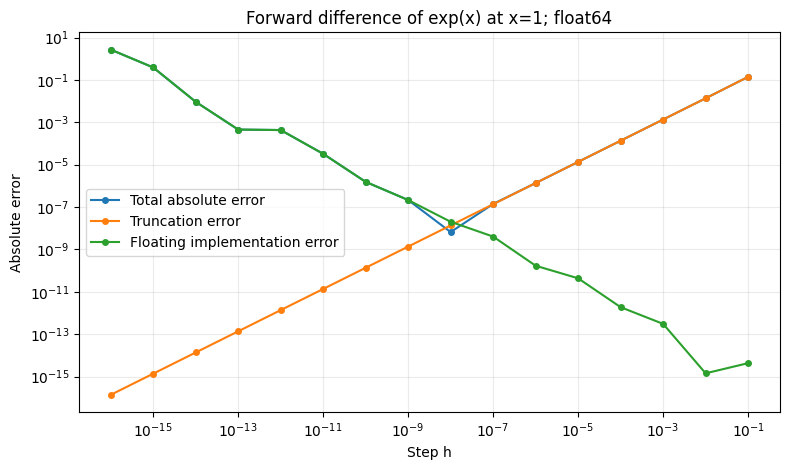

1.2耗时（秒）： 0.3158595000022615


In [8]:
# 1.2 误差图表与比较
fig, ax = plt.subplots(figsize=(8, 4.8))
for key, label in [('total_error', 'Total absolute error'),
                   ('truncation', 'Truncation error'),
                   ('implementation', 'Floating implementation error')]:
    ax.loglog([row['h'] for row in difference_rows],
              [row[key] for row in difference_rows], 'o-', label=label, markersize=4)
ax.set(xlabel='Step h', ylabel='Absolute error', title='Forward difference of exp(x) at x=1; float64')
ax.grid(True, which='both', alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'A2组-差分误差.png', dpi=180)
plt.show()
section_times['1.2'] = time.perf_counter() - section_started
print('1.2耗时（秒）：', section_times['1.2'])

### 结果解释与本节结论

应提供的证据：给出步长、两类误差的解释及实际曲线；记录误差不再下降的区间，不能只给最佳结果。

在 $x=10^{16}$ 处，直接平方根差为0，相对误差为1；有理化式为 $5\times10^{-9}$，相对误差约为 $4.59226\times10^{-17}$。高精度参考约为 $4.999999999999999875\times10^{-9}$。

| 步长 | 近似导数 | 总绝对误差 | 实际取样增量 |
| --- | --- | --- | --- |
| 1e-01 | 2.85884195487388 | 1.40560126e-01 | 1.00000000e-01 |
| 1e-02 | 2.73191865578712 | 1.36368273e-02 | 1.00000000e-02 |
| 1e-03 | 2.71964142253323 | 1.35959407e-03 | 1.00000000e-03 |
| 1e-04 | 2.71841774708292 | 1.35918624e-04 | 1.00000000e-04 |
| 1e-05 | 2.71829541995672 | 1.35914977e-05 | 1.00000000e-05 |
| 1e-06 | 2.71828318743061 | 1.35897157e-06 | 1.00000000e-06 |
| 1e-07 | 2.71828196840573 | 1.39946688e-07 | 1.00000000e-07 |
| 1e-08 | 2.71828182185629 | 6.60275094e-09 | 9.99999994e-09 |
| 1e-09 | 2.7182820439009 | 2.15441854e-07 | 1.00000008e-09 |
| 1e-10 | 2.71828337616853 | 1.54770948e-06 | 1.00000008e-10 |
| 1e-11 | 2.71831446241322 | 3.26339542e-05 | 1.00000008e-11 |
| 1e-12 | 2.71871414270208 | 4.32314243e-04 | 1.00008890e-12 |
| 1e-13 | 2.71782596428238 | 4.55864177e-04 | 9.99200722e-14 |
| 1e-14 | 2.70894418008538 | 9.33764837e-03 | 9.99200722e-15 |
| 1e-15 | 3.10862446895044 | 3.90342640e-01 | 1.11022302e-15 |
| 1e-16 | 0 | 2.71828183e+00 | 0.00000000e+00 |

![前向差分误差](图片/A2组-差分误差.png)

*图01-2：$e^x$ 在 $x=1$ 处的float64前向差分，双对数坐标。横轴为步长，纵轴为误差绝对值；输入及误差均无量纲。*

本次最小总绝对误差约为 $6.60275\times10^{-9}$，对应 $h=10^{-8}$。再减小步长，误差总体回升；$h=10^{-16}$ 时实际取样增量为0。设准确十进制步长下的差分为 $D_h$，浮点结果为 $\widehat D_h$，则

$$\widehat D_h-e=(D_h-e)+(\widehat D_h-D_h).$$

两项分别是截断误差和浮点实现误差，后者含步长、取样点和函数运算的误差。它们可以部分抵消，绝对值不必相加等于总绝对误差。实验覆盖表中16个步长。

### 易错点与讨论

待核验的风险：步长越小不一定越准；代数等价不保证浮点实现同样可靠。

本次扫描在 $h=10^{-8}$ 附近取得较小误差，而 $h=10^{-16}$ 时取样点重合。因此，步长需要平衡截断与舍入。有理化式显式保留分子1；若仍把分子写成浮点 `(x+1)-x`，就会再次丢失增量。

**随堂提问：** 设计一道同时包含有理化和差分步长选择的题，要求解释失败情形。

在float64中分别计算 $g(10^{16})$ 的直接式、有理化式，以及 $e^x$ 在1处步长 $10^{-8}$、$10^{-16}$ 的前向差分。若认为“步长更小就更准”，应解释为何后一个差分变为0。关键在于 $1+h$ 已舍入为1，而有理化保留了准确分子1。


### 1.2 实际运行记录

运行日期：2026-10-19；环境为Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 代码单元按模板顺序执行，第1.2节结果已保存到本Notebook输出与 `实验输出/`，图片保存到 `图片/`。表中误差与本节推导及预测一致。实际版本、每节耗时和数值检查结果见执行输出。本次为AI辅助计算与整理，学生人工核对及B/C记录仍按模板保留。


## 1.3 条件数与稳定性（2学时）

**本节目标：** 能分清问题敏感性与算法误差传播。

### 概念讲解：把问题说明白

填写提示：条件数是问题的性质，稳定性与算法有关；选择一个标量例子，避免在本章展开矩阵后向误差理论。

一个答案不准确，可能是因为输入稍有偏差就会使答案发生很大变化，也可能是算法在计算过程中放大了舍入误差。

**条件性**描述数学问题对输入扰动的敏感程度，属于问题本身；**稳定性**描述算法处理计算误差的能力，属于算法。[Higham 对数值稳定性的说明](https://nhigham.com/2020/08/04/what-is-numerical-stability/)给出了这一区分及其误差分析含义。

例如，

$$
q(x)=\frac1{1-x}
$$

在 $x$ 接近1时非常敏感：输入发生微小变化，准确函数值就可能明显改变。相反，开场中的平方根差对较大 $x$ 的相对扰动并不敏感，直接计算却仍然失败。

稳定的算法应将计算过程中附加的误差控制在与所用精度和问题敏感性相称的水平。本节以标量扰动与两种表达式为主，不展开矩阵后向误差理论。

### 关键推导：让结论有依据

推导任务：在条件允许时推导标量相对条件数 |x f′(x)/f(x)|；指出x或f(x)为零时相对表述的限制。

设 $f$ 在 $x$ 处可微，则

$$
f(x+\Delta x)-f(x)
=f'(x)\Delta x+o(|\Delta x|).
$$

当 $x\ne0$ 且 $f(x)\ne0$ 时，比较输入和输出的相对变化，得到**相对条件数**：

$$
\boxed{\kappa_{\mathrm{rel}}(x)=\left|\frac{xf'(x)}{f(x)}\right|}.
$$

对充分小的扰动，有一阶近似

$$
\frac{|\Delta f|}{|f(x)|}
\approx\kappa_{\mathrm{rel}}(x)\frac{|\Delta x|}{|x|}.
$$

条件数越大，输入的相对误差越容易转化为较大的输出相对误差。若讨论绝对误差，相应的**绝对条件数**为

$$
\kappa_{\mathrm{abs}}(x)=|f'(x)|.
$$

当输入或输出为零、相对尺度不适用时，可以使用绝对条件数。条件数的含义始终与所选的输入、输出及误差尺度联系在一起。

对 $q(x)=1/(1-x)$，有

$$
q'(x)=\frac1{(1-x)^2},\qquad
\kappa_q(x)=\left|\frac{x}{1-x}\right|.
$$

当 $x\to1$ 时，条件数趋于无穷。因此，在1附近求这个函数值是一个相对病态的问题。

再看 $g(x)=\sqrt{x+1}-\sqrt x$。当 $x>0$ 时，

$$
\begin{aligned}
g'(x)
&=\frac1{2\sqrt{x+1}}-\frac1{2\sqrt x}\\
&=-\frac{g(x)}{2\sqrt x\sqrt{x+1}},
\end{aligned}
$$

从而

$$
\kappa_g(x)=\frac12\sqrt{\frac{x}{x+1}}<\frac12.
$$

当 $x\to\infty$ 时，条件数趋近 $1/2$。因此，输入 $x$ 的小相对扰动只会引起同量级的输出相对变化。开场计算失败的原因，应当从算法中寻找。

这里把 $x$ 作为唯一输入，并把常数1视为准确常数。若将两个平方根的值看作可独立扰动的两个输入，讨论的就变成了另一个数学问题。

### 实验设计：先预测，再运行

实验任务：对同一问题施加不同大小的输入扰动，比较输出变化；再对同一输入比较两种等价算法。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 输入扰动放大率预计趋近9999；良态的平方根差也可能因直接式失去精度。 |
| 输入、参数、单位、数据来源与划分 | Decimal输入0.9999及正扰动 $10^{-6},10^{-8},10^{-10}$；算法比较输入0、1、 $10^8$、 $10^{16}$。无量纲。 |
| 独立参考解/基线及选择理由 | q的有限扰动闭式关系；g的120位Decimal原始差式。 |
| 误差指标、容差及其依据 | 相对变化放大率与闭式值的Decimal差小于 $10^{-65}$；有理化相对误差小于 $10^{-14}$。 |
| 环境、种子、设备与运行预算 | Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 |

实现见[A2组-实验.ipynb](A2组-实验.ipynb)第1.3节，代码单元索引17、18、19（从0计）。本次已顺序运行并保存表格、数值记录及相关图。


In [9]:
# 1.3 输入与独立参考
section_started = time.perf_counter()
print('条件性输入：x=0.9999，d=1e-6、1e-8、1e-10；算法输入：0、1、1e8、1e16。')
print('参考：有限扰动恒等式与120位Decimal平方根差。')

条件性输入：x=0.9999，d=1e-6、1e-8、1e-10；算法输入：0、1、1e8、1e16。
参考：有限扰动恒等式与120位Decimal平方根差。


In [10]:
# 1.3 方法实现与运行
perturbation_rows = []
with localcontext() as ctx:
    ctx.prec = 80
    x = Decimal('0.9999')
    value = 1 / (1 - x)
    kappa_q = abs(x / (1 - x))
    perturbation_checks = []
    for d_text in ('1e-6', '1e-8', '1e-10'):
        d = Decimal(d_text)
        relative_input = abs(d / x)
        relative_output = abs((1 / (1 - x - d) - value) / value)
        amplification = relative_output / relative_input
        closed = abs(x / (1 - x - d))
        perturbation_checks.append(abs(amplification - closed) < Decimal('1e-65'))
        perturbation_rows.append({
            'd': d_text, 'input_relative': str(relative_input),
            'output_relative': str(relative_output),
            'amplification': str(amplification), 'closed_form': str(closed),
        })
    singular_point = x + Decimal('1e-4')
    assert singular_point == 1
checks['finite_perturbation_identity'] = all(perturbation_checks)
assert checks['finite_perturbation_identity']
show_table(perturbation_rows, [('d', '扰动'), ('input_relative', '输入相对变化'),
    ('output_relative', '输出相对变化'), ('amplification', '放大率')])
save_csv('条件数扰动.csv', perturbation_rows)
print('局部相对条件数：', kappa_q, '；d=1e-4 后到达奇点：', singular_point)



algorithm_rows = []
for x_text in ('0', '1', '1e8', '1e16'):
    x = np.float64(x_text)
    reference = g_reference(x_text, 120)
    for method, value in (
        ('direct', np.sqrt(x + np.float64(1)) - np.sqrt(x)),
        ('rationalized', rationalized_difference(x))):
        with localcontext() as ctx:
            ctx.prec = 120
            absolute_error = abs(decimal_float(value) - reference)
            relative_error = absolute_error / abs(reference)
        algorithm_rows.append({
            'x': x_text, 'method': method, 'value': float(value),
            'absolute_error': float(absolute_error), 'relative_error': float(relative_error),
        })
checks['algorithm_comparison'] = all(
    row['relative_error'] < 1e-14 for row in algorithm_rows if row['method'] == 'rationalized')
assert checks['algorithm_comparison']
show_table(algorithm_rows, [('x', '输入'), ('method', '表达式'), ('value', '结果'),
    ('absolute_error', '绝对误差'), ('relative_error', '相对误差')])
save_csv('算法误差.csv', algorithm_rows)

| 扰动 | 输入相对变化 | 输出相对变化 | 放大率 |
| --- | --- | --- | --- |
| 1e-6 | 1.000100010001E-6 | 1.010101010101E-2 | 1.010000000000E+4 |
| 1e-8 | 1.000100010001E-8 | 1.000100010001E-4 | 1.000000000000E+4 |
| 1e-10 | 1.000100010001E-10 | 1.000001000001E-6 | 9.999009999010E+3 |

局部相对条件数： 9999 ；d=1e-4 后到达奇点： 1.0000


| 输入 | 表达式 | 结果 | 绝对误差 | 相对误差 |
| --- | --- | --- | --- | --- |
| 0 | direct | 1 | 0 | 0 |
| 0 | rationalized | 1 | 0 | 0 |
| 1 | direct | 0.41421356237309515 | 9.6672933134529135e-17 | 2.333891062877676e-16 |
| 1 | rationalized | 0.41421356237309509 | 4.1161781903271301e-17 | 9.9373332122321013e-17 |
| 1e8 | direct | 5.0000000555883162e-05 | 6.808831610986137e-13 | 1.3617663256016433e-08 |
| 1e8 | rationalized | 4.9999999874999996e-05 | 4.5057014229664403e-21 | 9.0114028684613872e-17 |
| 1e16 | direct | 0 | 5.0000000000000001e-09 | 1 |
| 1e16 | rationalized | 5.0000000000000001e-09 | 2.2961280415064237e-25 | 4.5922560830128472e-17 |

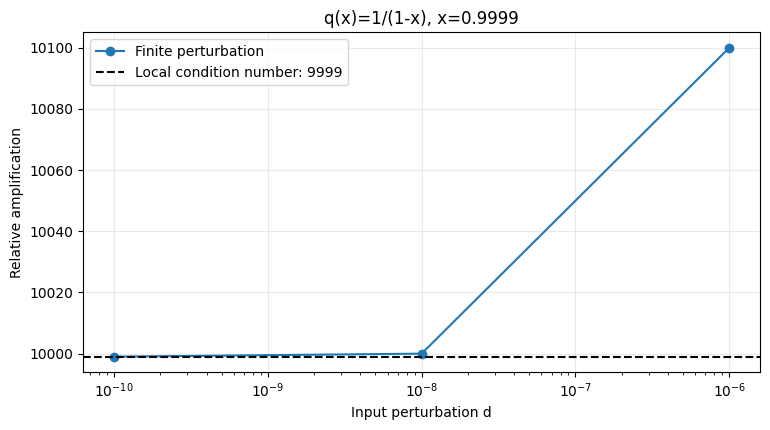

1.3耗时（秒）： 0.24522869999782415


In [11]:
# 1.3 误差图表与比较
fig, ax = plt.subplots(figsize=(7.8, 4.4))
ax.semilogx([float(row['d']) for row in perturbation_rows],
            [float(row['amplification']) for row in perturbation_rows], 'o-', label='Finite perturbation')
ax.axhline(float(kappa_q), color='black', linestyle='--', label='Local condition number: 9999')
ax.set(xlabel='Input perturbation d', ylabel='Relative amplification', title='q(x)=1/(1-x), x=0.9999')
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'A2组-条件数扰动.png', dpi=180)
plt.show()
section_times['1.3'] = time.perf_counter() - section_started
print('1.3耗时（秒）：', section_times['1.3'])

### 结果解释与本节结论

应提供的证据：分别填写输入扰动放大表和算法误差表，说明哪个证据对应条件数、哪个对应稳定性。

条件性实验在 $x=0.9999$ 处使用高精度运算，$q(x)=10000$，局部相对条件数为9999。

| 扰动 | 输入相对变化 | 输出相对变化 | 放大率 |
| --- | --- | --- | --- |
| 1e-6 | 1.0001000100E-6 | 1.0101010101E-2 | 10100.0000000000 |
| 1e-8 | 1.0001000100E-8 | 1.0001000100E-4 | 10000.0000000000 |
| 1e-10 | 1.0001000100E-10 | 1.0000010000E-6 | 9999.0099990100 |

有限扰动满足

$$\frac{q(x+d)-q(x)}{q(x)}=\frac d{1-x-d},\qquad R(d)=\left|\frac{x}{1-x-d}\right|.$$

扰动减小时放大率趋近9999。$d=10^{-4}$ 会使输入到达奇点1，函数无定义。

固定同一个 $g(x)$ 和输入，只改变表达式，得到以下算法误差表。


| 输入 | 表达式 | 结果 | 绝对误差 | 相对误差 |
| --- | --- | --- | --- | --- |
| 0 | direct | 1 | 0.000000e+00 | 0.000000e+00 |
| 0 | rationalized | 1 | 0.000000e+00 | 0.000000e+00 |
| 1 | direct | 0.414213562373095 | 9.667293e-17 | 2.333891e-16 |
| 1 | rationalized | 0.414213562373095 | 4.116178e-17 | 9.937333e-17 |
| 1e8 | direct | 5.00000005558832e-05 | 6.808832e-13 | 1.361766e-08 |
| 1e8 | rationalized | 4.9999999875e-05 | 4.505701e-21 | 9.011403e-17 |
| 1e16 | direct | 0 | 5.000000e-09 | 1.000000e+00 |
| 1e16 | rationalized | 5e-09 | 2.296128e-25 | 4.592256e-17 |

前表改变输入，反映条件性；后表改变计算方式，反映算法行为。$g$ 在大输入处的相对条件数约为 $1/2$，因此直接式的大误差应从计算过程解释。

### 易错点与讨论

待核验的风险：不能把某个算法很准确当作问题良态的证明，也不能把病态问题直接叫作错误算法。

条件数通过改变输入、比较对应的准确输出来研究；算法误差通过固定输入、比较计算结果与独立参考来研究。$g$ 在大输入处的相对条件数接近 $1/2$，直接式却输出0，表明良态问题也需要合适算法。

**随堂提问：** 给出一组实验结果，让读者判断观察到的是问题敏感性还是算法不稳定。

甲将 $q(0.9999)$ 的输入增加 $10^{-8}$，观察到约一万倍的相对变化放大；乙固定 $g(10^{16})$，将表达式有理化后从0得到约 $5\times10^{-9}$。甲对应问题敏感性，乙对应算法表现。应分别说明比较中改变的对象。


### 1.3 实际运行记录

运行日期：2026-10-19；环境为Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 代码单元按模板顺序执行，第1.3节结果已保存到本Notebook输出与 `实验输出/`，图片保存到 `图片/`。表中误差与本节推导及预测一致。实际版本、每节耗时和数值检查结果见执行输出。本次为AI辅助计算与整理，学生人工核对及B/C记录仍按模板保留。


## 1.4 AI关联：训练中的数值问题（2学时）

**本节目标：** 能解释训练中上溢、下溢和不稳定损失计算的风险。

### 概念讲解：把问题说明白

填写提示：以softmax或log-sum-exp为主例；联系梯度尺度与精度选择，完整训练和混合精度工程作为选做。

分类模型常输出一组实数 $z_1,\ldots,z_n$，称为 logits，即未经归一化的类别分数。softmax 将它们转换为概率：

$$
p_i=\frac{e^{z_i}}{\sum_{j=1}^n e^{z_j}}.
$$

对于有限的实数 logits，准确概率满足 $0<p_i<1$（$n\ge2$），且概率和为1。然而，最终结果有界，并不意味着中间计算也有界。

例如，$z=[1000,1001,1002]$ 的 softmax 概率完全正常，但直接计算 $e^{1000}$ 就会使 `float64` 上溢。两种格式的最大有限数及其自然对数约为：

| 类型 | 最大有限数 | 最大有限数的自然对数 |
| --- | --- | --- |
| `float32` | $3.40\times10^{38}$ | $88.72$ |
| `float64` | $1.80\times10^{308}$ | $709.78$ |

一旦指数上溢为 `inf`，后续的 `inf/inf` 就会得到 NaN。反过来，若 logits 全为很大的负数，直接计算的指数可能全部下溢为0，随后出现 $0/0$。

### 关键推导：让结论有依据

推导任务：推导减去最大值的softmax改写，写明实数等价性及它能缓解的数值问题。

取

$$
m=\max_jz_j.
$$

在准确算术中，分子、分母同时除以 $e^m$，得到

$$
\boxed{p_i=\frac{e^{z_i-m}}{\sum_j e^{z_j-m}}}.
$$

现在每个指数的输入都不大于0，并且至少有一项为 $e^0=1$。因此，各指数均不大于1，分母满足

$$
1\le\sum_j e^{z_j-m}\le n.
$$

在移位减法和求和未溢出的通常计算范围内，这一改写避免了指数上溢和分母因全部下溢而变成零。它也是 [SciPy softmax 实现](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html)所采用的基本方法。

很小的概率仍可能下溢为零。如果后面还要取对数，就应直接计算对数概率或损失。

定义 log-sum-exp 函数

$$
L(z)=\log\!\left(\sum_j e^{z_j}\right).
$$

同样的移位给出

$$
L(z)=m+\log\!\left(\sum_j e^{z_j-m}\right).
$$

若真实类别为 $y$，单个样本的交叉熵损失为

$$
\ell=-\log p_y=L(z)-z_y.
$$

代入移位公式，并安排计算顺序，得到

$$
\boxed{\ell=(m-z_y)+\log\!\left(\sum_j e^{z_j-m}\right)}.
$$

先求 $m-z_y$，可以保留后面的较小对数项，避免先计算“大数加小量”，再减去接近的大数。

考虑

$$
z=[1000,0,-1000],
$$

以第三类为真实类别。移位后得到 $[0,-1000,-2000]$。在 `float64` 中，后两项的指数都下溢为0，softmax 返回 $[1,0,0]$。如果先取第三类概率再计算 $-\log p_y$，结果是无穷；直接使用上面的损失公式，则得到2000。

准确的损失为

$$
\ell=2000+\log(1+e^{-1000}+e^{-2000}),
$$

极接近2000。这说明：**一个无法用当前浮点格式保留的微小概率，其对数仍可能被准确地近似。**

对交叉熵的准确数学表达式求导，有

$$
\frac{\partial\ell}{\partial z_i}=p_i-\mathbf1_{\{i=y\}},
$$

其中指示函数在 $i=y$ 时为1，其余为0。这个简洁的梯度公式，也是 softmax 与交叉熵常被联合计算的重要原因。

### 实验设计：先预测，再运行

实验任务：使用包含大幅值的logits，对比直接指数与稳定实现；将故意溢出限制在明确标注的演示中，记录有限性和概率和。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 直接指数预计产生inf或全零，移位实现预计有限；微小概率可能为0而对数域损失有限。 |
| 输入、参数、单位、数据来源与划分 | 三组logits为[1000,1001,1002]、[-1000,-1001,-1002]、[1000,0,-1000]；两种精度。参数更新1减 $10^{-8}$；梯度核验步长 $10^{-5}$。 |
| 独立参考解/基线及选择理由 | 前两组80位Decimal原始指数归一化、120位复核；极端组500位、600位复核，以分辨1附近约 $10^{-435}$ 的变化。 |
| 误差指标、容差及其依据 | 有限性、概率和、最大绝对误差；float32容差 $10^{-6}$、float64容差 $10^{-14}$；损失绝对误差小于 $10^{-12}$；梯度绝对差小于 $10^{-8}$。 |
| 环境、种子、设备与运行预算 | Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 |

实现见[A2组-实验.ipynb](A2组-实验.ipynb)第1.4节，代码单元索引23、24、25（从0计）。本次已顺序运行并保存表格、数值记录及相关图。


In [12]:
# 1.4 输入与独立参考
section_started = time.perf_counter()
print('三组logits，float32/float64；参考精度：80→120位或500→600位。')
print('更新量1e-8；梯度核验z=[0.2,-0.4,0.7]、y=1、h=1e-5。')

三组logits，float32/float64；参考精度：80→120位或500→600位。
更新量1e-8；梯度核验z=[0.2,-0.4,0.7]、y=1、h=1e-5。


| logits | 类型 | 直接指数含inf | 直接概率含NaN | 移位概率 | 概率和 | 最大绝对误差 | 参考精度 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| [1000, 1001, 1002] | float32 | True | True | [0.09003057330846786, 0.2447284609079361, 0.6652409434318542] | 1 | 1.2342967641482143E-8 | 80 |
| [1000, 1001, 1002] | float64 | True | True | [0.09003057317038046, 0.24472847105479764, 0.6652409557748218] | 0.99999999999999989 | 1.0454416673312352E-16 | 80 |
| [-1000, -1001, -1002] | float32 | False | True | [0.6652409434318542, 0.2447284609079361, 0.09003057330846786] | 0.99999994039535522 | 1.2342967641482143E-8 | 80 |
| [-1000, -1001, -1002] | float64 | False | True | [0.6652409557748218, 0.24472847105479764, 0.09003057317038046] | 0.99999999999999989 | 1.0454416673312352E-16 | 80 |
| [1000, 0, -1000] | float32 | True | True | [1.0, 0.0, 0.0] | 1 | 5.0759588975494568E-435 | 500 |
| [1000, 0, -1000] | float64 | True | True | [1.0, 0.0, 0.0] | 1 | 5.0759588975494568E-435 | 500 |

80位参考的 1-p0： 0
500位参考的 1-p0： 5.075958897549E-435


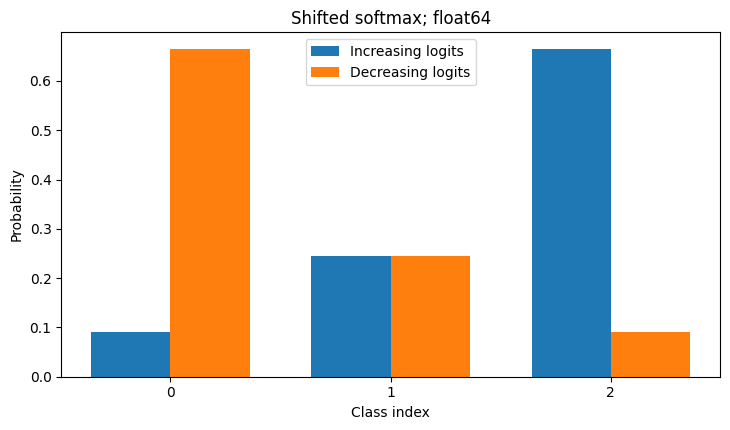

| 类型 | 第三类概率 | 先概率再取负对数 | 从logits计算损失 | 损失绝对误差 |
| --- | --- | --- | --- | --- |
| float32 | 0 | inf | 2000 | 5.075958897549E-435 |
| float64 | 0 | inf | 2000 | 5.075958897549E-435 |

| 类型 | 已存更新量 | 更新后保存值 | 已保存的变化量 | 1下方间隔 |
| --- | --- | --- | --- | --- |
| float32 | 9.9999999392252903e-09 | 1 | 0 | 5.9604644775390625e-08 |
| float64 | 1e-08 | 0.99999998999999995 | 1.0000000050247593e-08 | 1.1102230246251565e-16 |

准确损失相对于2000的高精度修正量约为： 5.075958897549E-435


| 分量 | 解析梯度 | 中心差分 | 绝对差 |
| --- | --- | --- | --- |
| 0 | 0.31274111296092955 | 0.31274111296220042 | 1.2708722962884167e-12 |
| 1 | -0.82836403812204551 | -0.8283640381190337 | 3.0118130212031247e-12 |
| 2 | 0.51562292516111607 | 0.51562292516793562 | 6.819544928760024e-12 |

最大梯度绝对差： 6.819544928760024e-12
解析梯度之和： 1.1102230246251565e-16


In [13]:
# 1.4 方法实现与运行
softmax_rows = []
probability_details = []
softmax_reference_checks = []
for values in ([1000, 1001, 1002], [-1000, -1001, -1002], [1000, 0, -1000]):
    precision = 500 if values == [1000, 0, -1000] else 80
    reference = decimal_softmax(values, precision)
    refined = decimal_softmax(values, 600 if precision == 500 else 120)
    with localcontext() as ctx:
        ctx.prec = 620
        relative_reference_change = max(abs(a - b) / abs(b) for a, b in zip(reference, refined))
    softmax_reference_checks.append(relative_reference_change < Decimal('1e-60'))
    for dtype, tolerance in ((np.float32, 1e-6), (np.float64, 1e-14)):
        z = np.array(values, dtype=dtype)
        with np.errstate(over='ignore', under='ignore', invalid='ignore', divide='ignore'):
            exp_direct = np.exp(z)
            direct_probability = exp_direct / np.sum(exp_direct, dtype=dtype)
        probability = stable_softmax(z)
        with localcontext() as ctx:
            ctx.prec = 620
            errors = [abs(decimal_float(p) - ref) for p, ref in zip(probability, reference)]
            relative_errors = [error / abs(ref) for error, ref in zip(errors, reference)]
            maximum_error = max(errors)
        normalization_error = abs(float(np.sum(probability, dtype=dtype)) - 1)
        passed = (bool(np.isfinite(probability).all()) and normalization_error < tolerance
                  and maximum_error < Decimal(str(tolerance)))
        assert passed
        row = {
            'logits': str(values), 'dtype': dtype.__name__,
            'direct_exp_has_inf': bool(np.isinf(exp_direct).any()),
            'direct_probability_has_nan': bool(np.isnan(direct_probability).any()),
            'probabilities': probability.tolist(),
            'probability_sum': float(np.sum(probability, dtype=dtype)),
            'normalization_error': normalization_error,
            'max_absolute_error_decimal': format(maximum_error, '.16E'),
            'reference_precision': precision, 'passed': passed,
        }
        softmax_rows.append(row)
        for index, (p, ref, error, relative_error) in enumerate(zip(probability, reference, errors, relative_errors)):
            probability_details.append({
                'logits': str(values), 'dtype': dtype.__name__, 'class_index': index,
                'probability': float(p), 'reference_decimal': str(ref),
                'absolute_error_decimal': format(error, '.16E'),
                'relative_error_decimal': format(relative_error, '.16E'),
            })
checks['softmax_reference_precision'] = all(softmax_reference_checks)
checks['softmax_cases'] = all(row['passed'] for row in softmax_rows)
checks['direct_softmax_demonstrations'] = all(row['direct_probability_has_nan'] for row in softmax_rows)
assert checks['softmax_reference_precision'] and checks['softmax_cases'] and checks['direct_softmax_demonstrations']
show_table(softmax_rows, [('logits', 'logits'), ('dtype', '类型'),
    ('direct_exp_has_inf', '直接指数含inf'), ('direct_probability_has_nan', '直接概率含NaN'),
    ('probabilities', '移位概率'), ('probability_sum', '概率和'),
    ('max_absolute_error_decimal', '最大绝对误差'), ('reference_precision', '参考精度')])
save_csv('softmax.csv', softmax_rows)
save_csv('softmax逐项误差.csv', probability_details)

with localcontext() as ctx:
    ctx.prec = 620
    rare80 = decimal_softmax([1000, 0, -1000], 80)
    rare500 = decimal_softmax([1000, 0, -1000], 500)
    print('80位参考的 1-p0：', 1 - rare80[0])
    print('500位参考的 1-p0：', format(1 - rare500[0], '.12E'))

fig, ax = plt.subplots(figsize=(7.4, 4.4))
for values, offset, label in (([1000, 1001, 1002], -0.18, 'Increasing logits'),
                              ([-1000, -1001, -1002], 0.18, 'Decreasing logits')):
    probability = stable_softmax(np.array(values, dtype=np.float64))
    ax.bar(np.arange(3) + offset, probability, width=0.36, label=label)
ax.set(xticks=[0, 1, 2], xlabel='Class index', ylabel='Probability', title='Shifted softmax; float64')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'A2组-softmax概率.png', dpi=180)
plt.show()

loss_rows, update_rows = [], []
with localcontext() as ctx:
    ctx.prec = 620
    rare_loss_reference = -decimal_softmax([1000, 0, -1000], 600)[2].ln()
    rare_loss_correction = rare_loss_reference - Decimal(2000)
for dtype in (np.float32, np.float64):
    z = np.array([1000, 0, -1000], dtype=dtype)
    probability = stable_softmax(z)
    with np.errstate(divide='ignore'):
        probability_loss = -np.log(probability[2])
    log_loss = stable_ce(z, 2)
    with localcontext() as ctx:
        ctx.prec = 620
        loss_error = abs(decimal_float(log_loss) - rare_loss_reference)
    loss_rows.append({
        'dtype': dtype.__name__, 'third_probability': float(probability[2]),
        'probability_loss': str(float(probability_loss)), 'log_loss': float(log_loss),
        'absolute_error_decimal': format(loss_error, '.12E'),
    })
    one = dtype(1)
    update = dtype('1e-8')
    updated = dtype(one - update)
    gap_below = float(one - np.nextafter(one, dtype(0)))
    update_rows.append({
        'dtype': dtype.__name__, 'update': float(update), 'stored_result': float(updated),
        'stored_change': float(one - updated), 'gap_below_one': gap_below,
    })
checks['log_domain_loss'] = all(row['log_loss'] == 2000.0 and row['probability_loss'] == 'inf'
    and Decimal(row['absolute_error_decimal']) < Decimal('1e-12') for row in loss_rows)
checks['parameter_update'] = (update_rows[0]['stored_result'] == 1.0
    and update_rows[1]['stored_result'] == float(np.float64('0.99999999')))
assert checks['log_domain_loss'] and checks['parameter_update']
show_table(loss_rows, [('dtype', '类型'), ('third_probability', '第三类概率'),
    ('probability_loss', '先概率再取负对数'), ('log_loss', '从logits计算损失'),
    ('absolute_error_decimal', '损失绝对误差')])
show_table(update_rows, [('dtype', '类型'), ('update', '已存更新量'),
    ('stored_result', '更新后保存值'), ('stored_change', '已保存的变化量'),
    ('gap_below_one', '1下方间隔')])
save_csv('交叉熵.csv', loss_rows)
save_csv('参数更新.csv', update_rows)
print('准确损失相对于2000的高精度修正量约为：', format(rare_loss_correction, '.12E'))

z = np.array([0.2, -0.4, 0.7], dtype=np.float64)
y, h = 1, np.float64('1e-5')
analytic = stable_softmax(z).copy()
analytic[y] -= 1
gradient_rows = []
for i in range(z.size):
    plus, minus = z.copy(), z.copy()
    plus[i] += h
    minus[i] -= h
    numerical = (stable_ce(plus, y) - stable_ce(minus, y)) / (2 * h)
    gradient_rows.append({
        'component': i, 'analytic': float(analytic[i]),
        'central_difference': float(numerical),
        'absolute_difference': float(abs(analytic[i] - numerical)),
    })
gradient_max_error = max(row['absolute_difference'] for row in gradient_rows)
checks['gradient'] = gradient_max_error < 1e-8
checks['gradient_sum_zero'] = abs(float(np.sum(analytic))) < 1e-14
translation_checks = []
for dtype, tolerance in ((np.float32, 1e-6), (np.float64, 1e-14)):
    base = np.array([0, 1, 2], dtype=dtype)
    translation_checks.append(bool(np.max(np.abs(
        stable_softmax(base) - stable_softmax(base + dtype(1000)))) < tolerance))
checks['translation_invariance'] = all(translation_checks)
assert checks['gradient'] and checks['gradient_sum_zero'] and checks['translation_invariance']
show_table(gradient_rows, [('component', '分量'), ('analytic', '解析梯度'),
    ('central_difference', '中心差分'), ('absolute_difference', '绝对差')])
save_csv('损失梯度.csv', gradient_rows)
print('最大梯度绝对差：', gradient_max_error)
print('解析梯度之和：', float(np.sum(analytic)))

In [14]:
# 1.4 误差图表与比较
section_times['1.4'] = time.perf_counter() - section_started
print('各节耗时（秒）：', section_times)
assert all(bool(value) for value in checks.values())
summary = {
    'environment': environment,
    'checks': {key: bool(value) for key, value in checks.items()},
    'best_scanned_h': best['h'],
    'best_scanned_absolute_error': best['total_error'],
    'rationalized_relative_error': str(stable_relative_error),
    'max_gradient_absolute_difference': gradient_max_error,
    'rare_loss_correction_decimal': format(rare_loss_correction, '.16E'),
}
data = {
    'range': range_rows, 'small_sums': small_sum_rows, 'ordered_sums': ordered_sum_rows,
    'differences': difference_rows, 'perturbations': perturbation_rows,
    'algorithms': algorithm_rows, 'softmax': softmax_rows,
    'probability_details': probability_details, 'losses': loss_rows,
    'updates': update_rows, 'gradients': gradient_rows, 'summary': summary,
}
(OUT / '实验数据.json').write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT / '实验汇总.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
show_table([{'check': name, 'passed': bool(value)} for name, value in checks.items()],
           [('check', '检查项'), ('passed', '结果')])
print('实验数据已保存到：', OUT)
(OUT / '运行耗时.json').write_text(json.dumps(section_times, ensure_ascii=False, indent=2), encoding='utf-8')

各节耗时（秒）： {'1.1': 0.01728279999952065, '1.2': 0.3158595000022615, '1.3': 0.24522869999782415, '1.4': 0.16423379999832832}


| 检查项 | 结果 |
| --- | --- |
| spacing_and_order | True |
| g_reference_80_120 | True |
| rationalization | True |
| difference_reference_80_120 | True |
| collapsed_sample | True |
| finite_perturbation_identity | True |
| algorithm_comparison | True |
| softmax_reference_precision | True |
| softmax_cases | True |
| direct_softmax_demonstrations | True |
| log_domain_loss | True |
| parameter_update | True |
| gradient | True |
| gradient_sum_zero | True |
| translation_invariance | True |

实验数据已保存到： C:\Users\jyhyo\Desktop\科学计算作业\工作\实验输出


121

### 结果解释与本节结论

应提供的证据：给出输入范围、dtype、是否出现inf/NaN及输出差异；说明局部稳定实现不能保证整个训练稳定。

| logits | 类型 | 直接指数含inf | 直接概率含NaN | 移位概率 | 概率和 | 最大绝对误差 |
| --- | --- | --- | --- | --- | --- | --- |
| [1000, 1001, 1002] | float32 | 是 | 是 | [0.09003057331, 0.2447284609, 0.6652409434] | 1 | 1.234297E-8 |
| [1000, 1001, 1002] | float64 | 是 | 是 | [0.09003057317, 0.2447284711, 0.6652409558] | 0.99999999999999989 | 1.045442E-16 |
| [-1000, -1001, -1002] | float32 | 否 | 是 | [0.6652409434, 0.2447284609, 0.09003057331] | 0.99999994039535522 | 1.234297E-8 |
| [-1000, -1001, -1002] | float64 | 否 | 是 | [0.6652409558, 0.2447284711, 0.09003057317] | 0.99999999999999989 | 1.045442E-16 |
| [1000, 0, -1000] | float32 | 是 | 是 | [1, 0, 0] | 1 | 5.075959E-435 |
| [1000, 0, -1000] | float64 | 是 | 是 | [1, 0, 0] | 1 | 5.075959E-435 |

直接实现对六种组合均出现NaN。全负数组的直接指数全部为0，其他两组有正指数上溢；移位后的结果均有限，并满足float32为 $10^{-6}$、float64为 $10^{-14}$ 的概率绝对误差与归一化容差。

第三组的后两类概率下溢为0，但从logits计算第三类交叉熵得到2000。准确损失为 $2000+\log(1+e^{-1000}+e^{-2000})$，比2000大约 $5.07596\times10^{-435}$。本例的极小误差以Decimal科学计数文本保存。

float32保存的 $1-10^{-8}$ 为1，float64保存为0.99999999。前者的更新量小于1下方浮点间隔的一半，会被舍去。对 $z=[0.2,-0.4,0.7]$、$y=1$ 的中心差分核验，最大梯度绝对差约 $6.82\times10^{-12}$，低于 $10^{-8}$。以上实验针对概率、损失和单次更新，不涉及完整网络训练。

### 易错点与讨论

待核验的风险：把loss下降、没有NaN或AI声称稳定当作数值正确的充分证据。

第三组移位softmax返回有限的 $[1,0,0]$，但两个微小概率的相对误差均为100%。无NaN和概率和接近1仍不足以判断每个分量的准确度；损失下降还受任务与优化过程影响。应结合目标量的误差和独立参考进行判断。

**随堂提问：** 设计一道AI建议采用直接指数计算的辨析题，要求人工改写并提供运行证据。

教学构造的建议是：“概率不超过1，直接计算指数不会溢出。”取 $z=[1000,1001,1002]$，先判断，再运行两种实现。建议混淆了最终比值与中间指数的范围；减最大值后指数输入不大于0，可以避免本例的上溢。


### 1.4 实际运行记录

运行日期：2026-10-19；环境为Python 3.12.14、NumPy 2.3.5、Matplotlib 3.9.2；Windows CPU。输入为确定性教学构造；模板固定随机种子2026，本例不抽样。每节通常数秒，实际用时由Notebook记录。 代码单元按模板顺序执行，第1.4节结果已保存到本Notebook输出与 `实验输出/`，图片保存到 `图片/`。表中误差与本节推导及预测一致。实际版本、每节耗时和数值检查结果见执行输出。本次为AI辅助计算与整理，学生人工核对及B/C记录仍按模板保留。


## 回到开场：用证据回答

**本章核心问题：** 当计算机告诉你答案是3.141592653589793时，你凭什么相信它？

开场的运行前预测是“有理化式更可靠”。第1.1节说明float64在 $10^{16}$ 附近的间隔为2；第1.2节Notebook给出直接式0和有理化式 $5\times10^{-9}$，后者相对高精度参考误差约 $4.59\times10^{-17}$；第1.3节推导出 $g$ 的相对条件数趋近 $1/2$。因此，差额是在直接计算的表示与运算过程中丢失的，有理化保留准确分子1。

漫画只帮助识别这一机制，不能代替数值分析。面对屏幕上的3.141592653589793，可信度来自输入准确性、问题敏感性、算法误差分析及独立检验，而不是显示位数本身。

## 本章小结与课后习题

围绕 **浮点数、条件数、稳定性** 各写一段：它解决什么问题、适用条件是什么、最容易混淆什么。其他方法说明与这三个概念的联系。

**浮点数。** 有限存储只能表示有限个数，单位舍入误差描述正规范围内单次最近舍入的相对误差。机器间隔随尺度变化，显示位数不等于有效精度；整段程序的误差还取决于误差传播。

**条件数。** 条件数描述问题对输入扰动的局部敏感性。标量相对公式要求输入及输出非零；较大条件数意味着输入中的小误差可能显著影响答案。改写算法不会改变同一输入模型下的问题条件数。

**稳定性。** 稳定性关注算法怎样处理计算中附加的误差。有理化避免微小差值的抵消，差分步长平衡截断与舍入，移位softmax及对数域损失控制指数范围；这些方法都需要结合计算目标和误差尺度选择。

课后题按四节对应填写到[A2组-习题.md](A2组-习题.md)，参考解答单独放在`A2组-习题参考解答.md`。

## 选读边界

后向误差分析不列为本章主线；可在第4章的残差讨论中简要联系，完整分析留作选读。

选读不计入本章8学时和最低完成要求。若添加附录，只在此处填写已有材料的名称和链接，不为了占位增加空文档。

## 参考资料、图片来源与AI使用

| 支撑的主张/公式/图片 | 作者、标题、版本/年份 | 页码/章节/链接 | 本组人工核对 |
| --- | --- | --- | --- |
| 0.1表示与显示 | Python Software Foundation，Python 3.12教程 | [第15章 Floating-Point Arithmetic](https://docs.python.org/3.12/tutorial/floatingpoint.html) | 未核对 |
| eps、正规及非正规数范围 | NumPy Developers，NumPy 2.3 | [numpy.finfo：Notes及Attributes](https://numpy.org/doc/2.3/reference/generated/numpy.finfo.html) | 未核对 |
| 高精度转换、exp与ln | Python Software Foundation，Python 3.12标准库 | [decimal：Decimal对象、from_float、exp、ln](https://docs.python.org/3.12/library/decimal.html) | 未核对 |
| 条件性与稳定性 | N. J. Higham，What Is Numerical Stability?，2020 | [前向误差与条件数说明](https://nhigham.com/2020/08/04/what-is-numerical-stability/) | 未核对 |
| 移位softmax | SciPy Developers，softmax文档；Blanchard等，2019预印本 | [Notes](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html)、[论文](https://arxiv.org/abs/1909.03469) | 未核对 |
| 图01-1 | 课程仓库初始化助手，概念示意 | `图片/A-章节导入.svg`，沿用模板原图 | 未核对 |
| 图01-2及数值表 | A2组配套Notebook，本次辅助计算 | `A2组-实验.ipynb`第1.1—1.4节；图由1.2节代码生成 | 未核对 |

漫画为仓库初始化助手绘制的概念示意，A组需结合最终正文核对并记录修改。AI建议与人工结论分开，本章对话分别记录到`A2组-AI对话记录.md`、`模板-B组-AI对话记录.md`、`模板-C组-AI对话记录.md`；A/B/C按轮换角色填写。
